# CELL 1: FÖRSTÅ DATABRICKS – NAVIGATOR, SPARK SQL OCH PERMANENTA TABELLER

In [0]:
# ========================================
# CELL 1: FÖRSTÅ DATABRICKS – NAVIGATOR, SPARK SQL OCH PERMANENTA TABELLER
# ========================================

print("=" * 70)
print("🚀 DATABRICKS – GRUNDLÄGGANDE KOD, SPARK SQL OCH NAVIGATOR")
print("=" * 70)

# ----------------------------------------
# DEL A: FÖRKLARING AV DATABRICKS NAVIGATOR (MENYN)
# ----------------------------------------
print("\n" + "=" * 70)
print("📂 DEL A: DATABRICKS NAVIGATOR – VAD FINNS I MENYN TILL VÄNSTER?")
print("=" * 70)

print("""
┌─────────────────────────────────────────────────────────────────────────────────────────────┐
│  MENYVAL          │  VAD GÖR MAN DÄR?                         │  NÄR ANVÄNDER MAN?           │
├───────────────────┼───────────────────────────────────────────┼──────────────────────────────┤
│  🏠 Workspace      │  Dina notebooks, mappar, filer            │  VARJE DAG – här skriver du kod│
│  🔍 Catalog        │  Databaser, tabeller, metadata            │  När du ska hitta eller skapa │
│                    │                                           │  permanenta tabeller          │
│  ⚙️ Compute        │  Kluster (beräkningsresurser)             │  När du startar/stoppar       │
│  📊 SQL Editor     │  Skriv och kör SQL-frågor                 │  När du bara vill SQL (ingen  │
│                    │                                           │  Python-kod)                  │
│  📈 Dashboards     │  Skapa delbara dashboards                 │  När du ska visa resultat för │
│                    │                                           │  ledning eller kollegor       │
│  🧪 Experiments    │  MLflow – logga experiment                │  När du tränar AI-modeller    │
│  📦 Models         │  Hantera AI-modeller                      │  När du ska deploy:a modeller │
│  🎯 Serving        │  Köra AI-modeller som API                 │  När modellen är i produktion │
│  📋 Jobs           │  Schemalägga pipelines                    │  När saker ska köras automatiskt│
│  🔌 Data Ingestion │  Ladda data från externa källor           │  När du hämtar API-data       │
└─────────────────────────────────────────────────────────────────────────────────────────────┘

   💡 VIKTIGAST FÖR DENNA KURS: Workspace (där du är nu), Catalog (dina tabeller), Compute (klustret)
""")

# ----------------------------------------
# DEL B: VAD ÄR SPARK SQL? (Förklaring)
# ----------------------------------------
print("\n" + "=" * 70)
print("📖 DEL B: VAD ÄR SPARK SQL?")
print("=" * 70)

print("""
   SPARK SQL = Sättet att använda SQL (vanliga databasfrågor) på dina DataFrames.
   
   🔹 Vad är SQL? – Structured Query Language – språket för att fråga databaser.
      Exempel: SELECT * FROM kunder WHERE ålder > 30
   
   🔹 Varför använda Spark SQL i Databricks?
      - Du kan använda SQL DIREKT utan att skriva Python-kod
      - Många dataanalytiker kan redan SQL – de behöver inte lära sig Python
      - Ibland är SQL enklare och snabbare att skriva för komplexa frågor
      - Du kan blanda Python och SQL i samma notebook
   
   🔹 Används Spark SQL i riktig produktion?
      ✅ JA! Det är en av de mest använda funktionerna i Databricks.
      Många företag (Einride, Volvo, Kry) använder Spark SQL dagligen för att:
      - Analysera stora datamängder
      - Bygga datapipelines
      - Förbereda data för AI-modeller
      - Skapa rapporter och dashboards
   
   🔹 Skillnad mellan Spark SQL och vanlig SQL:
      - Vanlig SQL fungerar på en databas (t.ex. MySQL, PostgreSQL)
      - Spark SQL fungerar på dina DataFrames och distribuerade data
      - Spark SQL kan bearbeta TERABYTES av data – vanlig SQL kraschar
""")

# ----------------------------------------
# DEL C: TVÅ SÄTT ATT ARBETA MED DATA – DATAFRAME VS SPARK SQL
# ----------------------------------------
print("\n" + "=" * 70)
print("🔄 DEL C: TVÅ SÄTT ATT ARBETA MED DATA")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  METOD 1: DATAFRAME API (PYTHON)              │  METOD 2: SPARK SQL (SQL)              │
   ├───────────────────────────────────────────────┼─────────────────────────────────────────┤
   │  df.filter("age > 30")                        │  spark.sql("SELECT * FROM personer     │
   │                                               │            WHERE age > 30")            │
   ├───────────────────────────────────────────────┼─────────────────────────────────────────┤
   │  df.groupBy("city").count()                   │  spark.sql("SELECT city, COUNT(*)      │
   │                                               │            FROM personer               │
   │                                               │            GROUP BY city")             │
   ├───────────────────────────────────────────────┼─────────────────────────────────────────┤
   │  df.select("name", "city")                    │  spark.sql("SELECT name, city          │
   │                                               │            FROM personer")             │
   └───────────────────────────────────────────────┴─────────────────────────────────────────┘
   
   💡 VILKEN SKA DU VÄLJA?
   - Gillar du Python → använd DataFrame API (df.filter(), df.select())
   - Gillar du SQL → använd Spark SQL (spark.sql("..."))
   - Båda fungerar! Spark SQL är bara ett annat sätt att skriva SAMMA sak.
""")

# ----------------------------------------
# DEL D: SKAPA EN DATAFRAME (DATA I MINNET)
# ----------------------------------------
print("\n" + "=" * 70)
print("📊 DEL D: SKAPA EN DATAFRAME (DATA I MINNET – INTE PERMANENT)")
print("=" * 70)

print("""
   En DataFrame är som en tabell i MINNET – inte en permanent databas.
   Den skapas i din notebook och försvinner när du stänger klustret.
   
   🔹 DataFrame i minnet (tillfällig) – som en Excel-fil öppen i RAM
   🔹 SQL-tabell (permanent) – sparad på disk, finns kvar efter omstart
   
   I denna del skapar vi en DataFrame DIREKT i koden (ingen fil behövs)
""")

# Skapa en enkel DataFrame från Python-lista
data = [("Anna", 32, "Stockholm"),
        ("Erik", 28, "Göteborg"),
        ("Sofia", 35, "Malmö")]

df = spark.createDataFrame(data, ["name", "age", "city"])

print("\n   ✅ DataFrame skapad i MINNET (ingen fil, ingen databas)!")
print(f"   📊 Data: {df.count()} rader, {len(df.columns)} kolumner")
display(df)

# ----------------------------------------
# DEL E: SPARK SQL – ANVÄND SQL PÅ DATAFRAME (Utan permanent tabell)
# ----------------------------------------
print("\n" + "=" * 70)
print("🪄 DEL E: SPARK SQL – ANVÄND SQL PÅ DATAFRAME (INGEN PERMANENT TABELL)")
print("=" * 70)

print("""
   För att använda SQL på en DataFrame måste du först skapa en tillfällig vy.
   En tillfällig vy är som ett ALIAS (smeknamn) för din DataFrame.
   
   🔹 createOrReplaceTempView() = gör DataFrame tillgänglig för SQL
   🔹 Detta skapar INGEN permanent tabell – bara en tillfällig referens
   🔹 När du stänger notebooken försvinner vyn
   
   Steg:
   1. df.createOrReplaceTempView('personer')  → skapa vy
   2. spark.sql("SELECT ... FROM personer")   → kör SQL på vyn
""")

# Skapa tillfällig vy (som ett "alias" för DataFrame)
df.createOrReplaceTempView("personer")
print("\n   ✅ Tillfällig vy 'personer' skapad (finns bara i denna notebook)")

# Exempel 1: Enkel SQL-fråga – filtrera
print("\n   📌 EXEMPEL 1: SQL-fråga – filtrera (WHERE)")
sql_result_1 = spark.sql("SELECT * FROM personer WHERE age > 30")
print("   SQL: SELECT * FROM personer WHERE age > 30")
display(sql_result_1)

# Exempel 2: SQL-fråga – gruppera (GROUP BY)
print("\n   📌 EXEMPEL 2: SQL-fråga – gruppera (GROUP BY)")
sql_result_2 = spark.sql("SELECT city, COUNT(*) as antal FROM personer GROUP BY city")
print("   SQL: SELECT city, COUNT(*) FROM personer GROUP BY city")
display(sql_result_2)

print("""
   💡 OBS! Dessa SQL-frågor körs på DATAFRAMEN (i minnet), inte på en permanent tabell.
   Ingen data sparas permanent – allt försvinner när du stänger klustret.
""")

# ----------------------------------------
# DEL F: SKAPA PERMANENT SQL-TABELL (SPARAS I CATALOG)
# ----------------------------------------
print("\n" + "=" * 70)
print("💾 DEL F: SKAPA PERMANENT SQL-TABELL (SPARAS I CATALOG)")
print("=" * 70)

print("""
   Skillnad mellan tillfällig vy och permanent tabell:
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  Tillfällig vy (TempView)                    │  Permanent tabell (Table)               │
   ├─────────────────────────────────────────────┼───────────────────────────────────────────┤
   │  createOrReplaceTempView()                   │  saveAsTable() eller spark.sql("CREATE")  │
   │  Syns bara i denna notebook                  │  Syns i Catalog (alla notebooks)         │
   │  Försvinner när du stänger klustret          │  Sparad på disk – finns efter omstart    │
   │  Delas inte med andra                        │  Delas med teamet                        │
   │  Används för temporär analys                 │  Används för produktionsdata             │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

table_name = "personer_permanent"

# Steg 1: Ta bort tabellen om den redan finns (så att koden kan köras flera gånger)
print(f"\n   🔧 Steg 1: Rensa bort gammal tabell om den finns")
spark.sql(f"DROP TABLE IF EXISTS {table_name}")
print(f"   ✅ Tabell '{table_name}' borttagen (om den fanns)")

# Steg 2: Skapa ny permanent tabell
print(f"\n   🔧 Steg 2: Skapa ny permanent tabell '{table_name}'")
df.write.saveAsTable(table_name)
print(f"   ✅ Permanent tabell '{table_name}' skapad!")

# Steg 3: Verifiera att tabellen finns
print(f"\n   🔧 Steg 3: Verifiera att tabellen finns i Catalog")
display(spark.sql(f"SELECT * FROM {table_name}"))

# Steg 4: Visa att tabellen syns i Catalog
print(f"\n   📍 Du hittar tabellen i Catalog → default → {table_name}")
print("   💡 Denna tabell finns kvar även efter att du startar om klustret!")

# ----------------------------------------
# DEL G: ARBETA MED PERMANENT TABELL – LÄS MED SPARK SQL
# ----------------------------------------
print("\n" + "=" * 70)
print("📖 DEL G: ARBETA MED PERMANENT TABELL – LÄS MED SPARK SQL")
print("=" * 70)

print("""
   När du har en permanent tabell kan du läsa den med Spark SQL från VILKEN notebook som helst!
   Du behöver inte skapa en DataFrame först – bara kör spark.sql() direkt.
""")

# Läs från permanent tabell
df_from_table = spark.sql(f"SELECT * FROM {table_name}")
print(f"\n   📌 LÄS: spark.sql('SELECT * FROM {table_name}')")
display(df_from_table)

# Gör en SQL-fråga direkt på den permanenta tabellen
print(f"\n   📌 SQL-fråga på permanent tabell: filtrera (WHERE age > 30)")
result = spark.sql(f"SELECT name, age FROM {table_name} WHERE age > 30")
display(result)

# ----------------------------------------
# DEL H: VISA ALLA TABELLER I DATABASEN
# ----------------------------------------
print("\n" + "=" * 70)
print("📋 DEL H: VISA ALLA TABELLER I DEFAULT-DATABASEN")
print("=" * 70)

print("""
   SHOW TABLES = visa alla tabeller i den aktuella databasen
   Detta är ett SQL-kommando som fungerar i Spark SQL
""")

display(spark.sql("SHOW TABLES"))

# ----------------------------------------
# DEL I: TA BORT EN TABELL (DROP TABLE)
# ----------------------------------------
print("\n" + "=" * 70)
print("🗑️ DEL I: TA BORT EN TABELL (DROP TABLE)")
print("=" * 70)

print("""
   DROP TABLE = ta bort en permanent tabell (raderar datan!)
   
   🔹 DROP TABLE IF EXISTS tabellnamn → tar bort om den finns (inget fel om den inte finns)
   🔹 Använd med försiktighet – detta går INTE att ångra!
""")

print(f"\n   📌 Exempel: spark.sql('DROP TABLE IF EXISTS {table_name}')")
print(f"   (Vi behåller tabellen just nu – vi behöver den senare)")

print("\n   💡 Om du vill ta bort tabellen senare, kör:")
print(f"      spark.sql('DROP TABLE IF EXISTS {table_name}')")

# ----------------------------------------
# SAMMANFATTNING
# ----------------------------------------
print("\n" + "=" * 70)
print("🎯 SAMMANFATTNING – VIKTIGASTE PUNKTERNA")
print("=" * 70)

print("""
   📌 DATAFRAME (tillfällig):
      df = spark.createDataFrame(data, ["kolumn1", "kolumn2"])
      → Data i MINNET – försvinner när du stänger klustret
   
   📌 TILLFÄLLIG VY (för att använda SQL på DataFrame):
      df.createOrReplaceTempView("namn")
      spark.sql("SELECT * FROM namn")
      → Gör DataFrame tillgänglig för SQL – FORTFARANDE tillfällig!
   
   📌 PERMANENT TABELL (sparas i Catalog):
      df.write.saveAsTable("tabellnamn")
      → Sparas på DISK – finns kvar efter omstart
   
   📌 LÄSA PERMANENT TABELL:
      df = spark.sql("SELECT * FROM tabellnamn")
      → Kan göras från VILKEN notebook som helst
   
   📌 TA BORT TABELL:
      spark.sql("DROP TABLE IF EXISTS tabellnamn")
      → Raderar datan permanent!
   
   📌 VISA ALLA TABELLER:
      display(spark.sql("SHOW TABLES"))
   
   📌 DATABRICKS MENY:
      - Workspace = dina notebooks
      - Catalog = dina permanenta tabeller
      - Compute = ditt kluster
   
   🚀 Spark SQL används i PRODUKTION av företag som Einride, Volvo och Kry!
""")

print("\n" + "=" * 70)
print("✅ KLART! Fortsätt till nästa cell för att ladda upp din SCB-CSV-fil")
print("=" * 70)

🚀 DATABRICKS – GRUNDLÄGGANDE KOD, SPARK SQL OCH NAVIGATOR

📂 DEL A: DATABRICKS NAVIGATOR – VAD FINNS I MENYN TILL VÄNSTER?

┌─────────────────────────────────────────────────────────────────────────────────────────────┐
│  MENYVAL          │  VAD GÖR MAN DÄR?                         │  NÄR ANVÄNDER MAN?           │
├───────────────────┼───────────────────────────────────────────┼──────────────────────────────┤
│  🏠 Workspace      │  Dina notebooks, mappar, filer            │  VARJE DAG – här skriver du kod│
│  🔍 Catalog        │  Databaser, tabeller, metadata            │  När du ska hitta eller skapa │
│                    │                                           │  permanenta tabeller          │
│  ⚙️ Compute        │  Kluster (beräkningsresurser)             │  När du startar/stoppar       │
│  📊 SQL Editor     │  Skriv och kör SQL-frågor                 │  När du bara vill SQL (ingen  │
│                    │                                           │  Python-kod)              

name,age,city
Anna,32,Stockholm
Erik,28,Göteborg
Sofia,35,Malmö



🪄 DEL E: SPARK SQL – ANVÄND SQL PÅ DATAFRAME (INGEN PERMANENT TABELL)

   För att använda SQL på en DataFrame måste du först skapa en tillfällig vy.
   En tillfällig vy är som ett ALIAS (smeknamn) för din DataFrame.
   
   🔹 createOrReplaceTempView() = gör DataFrame tillgänglig för SQL
   🔹 Detta skapar INGEN permanent tabell – bara en tillfällig referens
   🔹 När du stänger notebooken försvinner vyn
   
   Steg:
   1. df.createOrReplaceTempView('personer')  → skapa vy
   2. spark.sql("SELECT ... FROM personer")   → kör SQL på vyn


   ✅ Tillfällig vy 'personer' skapad (finns bara i denna notebook)

   📌 EXEMPEL 1: SQL-fråga – filtrera (WHERE)
   SQL: SELECT * FROM personer WHERE age > 30


name,age,city
Anna,32,Stockholm
Sofia,35,Malmö



   📌 EXEMPEL 2: SQL-fråga – gruppera (GROUP BY)
   SQL: SELECT city, COUNT(*) FROM personer GROUP BY city


city,antal
Stockholm,1
Göteborg,1
Malmö,1


... (5 outputs left out)

name,age
Anna,32
Sofia,35



📋 DEL H: VISA ALLA TABELLER I DEFAULT-DATABASEN

   SHOW TABLES = visa alla tabeller i den aktuella databasen
   Detta är ett SQL-kommando som fungerar i Spark SQL



database,tableName,isTemporary
default,model_performance_history,false
default,personer_permanent,false
default,temp_personer,false
,personer,true



🗑️ DEL I: TA BORT EN TABELL (DROP TABLE)

   DROP TABLE = ta bort en permanent tabell (raderar datan!)
   
   🔹 DROP TABLE IF EXISTS tabellnamn → tar bort om den finns (inget fel om den inte finns)
   🔹 Använd med försiktighet – detta går INTE att ångra!


   📌 Exempel: spark.sql('DROP TABLE IF EXISTS personer_permanent')
   (Vi behåller tabellen just nu – vi behöver den senare)

   💡 Om du vill ta bort tabellen senare, kör:
      spark.sql('DROP TABLE IF EXISTS personer_permanent')

🎯 SAMMANFATTNING – VIKTIGASTE PUNKTERNA

   📌 DATAFRAME (tillfällig):
      df = spark.createDataFrame(data, ["kolumn1", "kolumn2"])
      → Data i MINNET – försvinner när du stänger klustret
   
   📌 TILLFÄLLIG VY (för att använda SQL på DataFrame):
      df.createOrReplaceTempView("namn")
      spark.sql("SELECT * FROM namn")
      → Gör DataFrame tillgänglig för SQL – FORTFARANDE tillfällig!
   
   📌 PERMANENT TABELL (sparas i Catalog):
      df.write.saveAsTable("tabellnamn")
      → Sparas på DISK – 

# CELL 2: Steg-för-steg – Ladda upp CSV (SCB Arbetsmarknadsdata)

In [0]:
# ========================================
# CELL 2: UNITY CATALOG – LADDA UPP CSV (MED SPECIALTECKEN)
# ========================================

print("=" * 70)
print("📁 UNITY CATALOG – LADDA UPP CSV-FILER (STEG-FÖR-STEG)")
print("=" * 70)

# ----------------------------------------
# DEL A: VAD ÄR UNITY CATALOG? (FÖR NYBÖRJARE)
# ----------------------------------------
print("\n" + "=" * 70)
print("🔍 DEL A: VAD ÄR UNITY CATALOG?")
print("=" * 70)

print("""
   Unity Catalog är som en "förrådschef" för all din data i Databricks.
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  ENKEL FÖRKLARING:                                                                      │
   │                                                                                         │
   │  Tänk dig ett stort lagerhus med hyllor:                                                │
   │                                                                                         │
   │  📦 CATALOG = hela lagret (t.ex. 'python_grund')                                        │
   │     └── 📁 SCHEMA = en hylla i lagret (t.ex. 'default')                                 │
   │         └── 📄 TABELL = en låda på hyllan (t.ex. 'scb_arbetsmarknad')                   │
   │         └── 📁 VOLYM = en låda för filer (CSV, JSON, bilder)                            │
   │                                                                                         │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   💡 Varför behövs detta? För att företag ska kunna:
   - Styra vem som ser vilken data
   - Veta var data kommer ifrån
   - Följa regler som GDPR
   
   💡 Du har Unity Catalog för att du använt Snowflake/dbt tidigare.
   💡 Det går INTE att stänga av – men det är bra att lära sig!
""")

# ----------------------------------------
# DEL B: MED vs UTAN UNITY CATALOG
# ----------------------------------------
print("\n" + "=" * 70)
print("📊 DEL B: MED vs UTAN UNITY CATALOG")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  UTAN UNITY CATALOG (enkelt)            │  MED UNITY CATALOG (proffs)                  │
   ├─────────────────────────────────────────┼─────────────────────────────────────────────┤
   │  Dra och släpp CSV → Create Table       │  Catalog → Create volume → Upload → Table   │
   │  Inga specialkrav på åäö/mellanslag     │  Måste ta bort åäö, mellanslag, parenteser  │
   │  Data sparas i dold mapp                │  Data sparas i volym (synlig)               │
   │  Passar för testning                    │  Passar för team och produktion             │
   └─────────────────────────────────────────┴─────────────────────────────────────────────┘
   
   💡 DU HAR UNITY CATALOG – SÅ VI FORTSÄTTER MED DET!
""")

# ----------------------------------------
# DEL C: STEG-FÖR-STEG – LADDA UPP CSV (MED BILDER I TEXT)
# ----------------------------------------
print("\n" + "=" * 70)
print("📤 DEL C: STEG-FÖR-STEG – LADDA UPP CSV")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  STEG 1: SKAPA EN CATALOG (om du inte har en)                                          │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │   Catalog                                                                               │
   │   ├── 🔍 Search...                                                                      │
   │   ├── [+] ← KLICKA HÄR!                                                                │
   │   │     └── "Create a catalog"                                                         │
   │   │           └── Namn: python_grund                                                    │
   │   │                 └── Klicka "Create catalog"                                        │
   │   │                                                                                    │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  STEG 2: SKAPA EN VOLYM (för att lagra filen)                                          │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │   Catalog → python_grund → default                                                      │
   │   ├── Create ▼                                                                          │
   │   │     └── "Volume"                                                                   │
   │   │           └── Namn: data_files                                                      │
   │   │                 └── Klicka "Create"                                                │
   │   │                                                                                    │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  STEG 3: LADDA UPP FILEN TILL VOLYMEN                                                  │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │   Klicka på volymen 'data_files'                                                        │
   │   ├── "Upload"                                                                          │
   │   │     └── Dra din CSV-fil eller klicka "browse"                                      │
   │   │           └── Vänta tills uppladdningen är klar                                    │
   │   │                                                                                    │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  STEG 4: SKAPA TABELL FRÅN FILEN (i notebook)                                          │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │  file_path = "/Volumes/python_grund/default/data_files/din_fil.csv"                    │
   │                                                                                         │
   │  df = spark.read.format("csv") \                                                        │
   │      .option("header", "true") \                                                        │
   │      .option("inferSchema", "true") \                                                   │
   │      .option("encoding", "ISO-8859-1") \                                                │
   │      .load(file_path)                                                                  │
   │                                                                                         │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL D: SPECIALTECKEN – PROBLEM OCH LÖSNING
# ----------------------------------------
print("\n" + "=" * 70)
print("⚠️ DEL D: SPECIALTECKEN – PROBLEM OCH LÖSNING")
print("=" * 70)

print("""
   PROBLEM: Delta Lake tillåter INTE mellanslag, åäö, parenteser i kolumnnamn.
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  OGILTIGT                           │  GILTIGT                                         │
   ├─────────────────────────────────────┼─────────────────────────────────────────────────┤
   │  "anknytningsgrad till arbets..."   │  "anknytningsgrad_till_arbetsmarknaden"         │
   │  "Sysselsatta 15-74 år (AKU)..."    │  "Sysselsatta_15_74_ar_AKU_tusental"            │
   │  "tabellinnehåll"                   │  "tabellinnehall" (utan å)                       │
   │  "kön"                              │  "kon" (utan ö)                                   │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   LÖSNING – byt namn på kolumnerna efter inläsning:
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  for col in df.columns:                                                                │
   │      new_col = col.replace(" ", "_")              # byt mellanslag → _                  │
   │      new_col = new_col.replace("å", "a")          # å → a                              │
   │      new_col = new_col.replace("ä", "a")          # ä → a                              │
   │      new_col = new_col.replace("ö", "o")          # ö → o                              │
   │      new_col = new_col.replace("(", "")           # ta bort (                           │
   │      new_col = new_col.replace(")", "")           # ta bort )                           │
   │      new_col = new_col.replace("-", "_")          # - → _                               │
   │      df = df.withColumnRenamed(col, new_col)                                           │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL E: VANLIGA FEL OCH LÖSNINGAR
# ----------------------------------------
print("\n" + "=" * 70)
print("🔧 DEL E: VANLIGA FEL OCH LÖSNINGAR")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  FEL                         │  ORSAK                      │  LÖSNING                   │
   ├──────────────────────────────┼─────────────────────────────┼────────────────────────────┤
   │  "Create Table" grå          │  Inget catalog/schema valt  │  Välj catalog + schema     │
   │                              │  eller inget tabellnamn     │  + skriv tabellnamn        │
   ├──────────────────────────────┼─────────────────────────────┼────────────────────────────┤
   │  "Invalid characters"        │  Mellanslag eller åäö       │  Rensa kolumnnamn (se ovan)│
   ├──────────────────────────────┼─────────────────────────────┼────────────────────────────┤
   │  "File not found"            │  Fel sökväg                  │  Använd dbutils.fs.ls("/") │
   │                              │                             │  för att hitta rätt        │
   ├──────────────────────────────┼─────────────────────────────┼────────────────────────────┤
   │  "No such volume"            │  Volymen finns inte         │  Skapa volume först        │
   ├──────────────────────────────┼─────────────────────────────┼────────────────────────────┤
   │  "String cannot be cast"     │  Kolumnen är text, inte tal │  Använd .cast("float")     │
   └──────────────────────────────┴─────────────────────────────┴────────────────────────────┘
""")

# ----------------------------------------
# DEL F: VARFÖR LYSER "DATA INGESTION"?
# ----------------------------------------
print("\n" + "=" * 70)
print("💡 DEL F: VARFÖR LYSER 'DATA INGESTION'?")
print("=" * 70)

print("""
   Data Ingestion är en meny för AUTOMATISK datahämtning.
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  VAD KAN DATA INGESTION GÖRA?                                                          │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  🔄 Hämta data från AWS S3, Azure, GCP (molnlagring)                                   │
   │  🔄 Hämta data från Snowflake, Redshift, BigQuery (databaser)                          │
   │  🔄 Hämta data från API:er (schemalagt – t.ex. varje natt)                              │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   💡 NÄR SYNS DATA DÄR?
   - Om du redan har data i molnet (AWS, Azure) → den syns där
   - Om du laddar upp manuellt (som vi gjorde) → den syns INTE där
   
   💡 I DIN SITUATION: Data Ingestion är tom – det är HELT OK!
   Du behöver inte använda Data Ingestion för denna kurs.
""")

# ----------------------------------------
# DEL G: HELA LÖSNINGEN – LADDA UPP OCH RENSA (KOD)
# ----------------------------------------
print("\n" + "=" * 70)
print("💻 DEL G: HELA LÖSNINGEN – LADDA UPP OCH RENSA")
print("=" * 70)

print("""
   # Steg 1: Läs in filen från volymen
   file_path = "/Volumes/python_grund/default/data_files/scb_arbetsmarknad.csv"
   
   df = spark.read.format("csv") \\
       .option("header", "true") \\
       .option("inferSchema", "true") \\
       .option("encoding", "ISO-8859-1") \\
       .load(file_path)
   
   # Steg 2: Rensa kolumnnamn (ta bort specialtecken)
   rename_map = {
       "anknytningsgrad till arbetsmarknaden": "anknytningsgrad",
       "Sysselsatta 15-74 år (AKU), 1000-tal": "sysselsatta_tusental",
       "kön": "kon",
       "år": "ar",
       "tabellinnehåll": "tabellinnehall"
   }
   
   for old, new in rename_map.items():
       if old in df.columns:
           df = df.withColumnRenamed(old, new)
   
   # Steg 3: Spara som permanent tabell
   df.write.mode("overwrite").saveAsTable("python_grund.default.scb_arbetsmarknad")
   
   print("✅ Tabell skapad!")
""")

# ----------------------------------------
# DEL H: SAMMANFATTNING
# ----------------------------------------
print("\n" + "=" * 70)
print("🎯 DEL H: SAMMANFATTNING")
print("=" * 70)

print("""
   ✅ Unity Catalog = Databricks system för datasäkerhet (standard i proffslivet)
   ✅ Du har det aktiverat – det går inte att stänga av
   ✅ Catalog → Schema → Volume/Tabell är hierarkin
   ✅ Specialtecken (åäö, mellanslag) måste tas bort
   ✅ Data Ingestion är för automatisk datahämtning (behövs inte här)
   ✅ Du har redan laddat upp din data korrekt!
   
   🚀 Nästa cell: Vi använder datan för visualisering!
""")

print("\n" + "=" * 70)
print("✅ KLART! Fortsätt till cell 3 för visualisering")
print("=" * 70)

📁 UNITY CATALOG – LADDA UPP CSV-FILER (STEG-FÖR-STEG)

🔍 DEL A: VAD ÄR UNITY CATALOG?

   Unity Catalog är som en "förrådschef" för all din data i Databricks.
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  ENKEL FÖRKLARING:                                                                      │
   │                                                                                         │
   │  Tänk dig ett stort lagerhus med hyllor:                                                │
   │                                                                                         │
   │  📦 CATALOG = hela lagret (t.ex. 'python_grund')                                        │
   │     └── 📁 SCHEMA = en hylla i lagret (t.ex. 'default')                                 │
   │         └── 📄 TABELL = en låda på hyllan (t.ex. 'scb_arbetsmarknad')                   │
   │         └── 📁 VOLYM = en låda för filer (CSV, JSON, bilder)                

<>:67: SyntaxWarning: invalid escape sequence '\ '
<>:67: SyntaxWarning: invalid escape sequence '\ '
/home/spark-3aa00075-e3ae-451c-a29b-77/.ipykernel/2068/command-7375525245444166-3762567836:67: SyntaxWarning: invalid escape sequence '\ '
  print("""


In [0]:
# ========================================
# CELL 2: UNITY CATALOG – LADDA UPP CSV-FILER
# ========================================

print("=" * 70)
print("📁 UNITY CATALOG – SÅ HÄR LADDAR DU UPP CSV-FILER")
print("=" * 70)

# ----------------------------------------
# DEL A: VAD ÄR UNITY CATALOG?
# ----------------------------------------
print("\n" + "=" * 70)
print("🔍 DEL A: VAD ÄR UNITY CATALOG?")
print("=" * 70)

print("""
   Unity Catalog är Databricks lösning för datasäkerhet och datastyrning.
   Det är som en "katalog" som håller reda på ALL din data och vem som får se den.
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  VAD GÖR UNITY CATALOG?                                                                │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  ✅ Håller reda på var data finns (catalog → schema → tabell → volym → fil)             │
   │  ✅ Vem som får se vilken data (behörigheter)                                           │
   │  ✅ Varifrån datan kommer (data lineage)                                                │
   │  ✅ Vilka ändringar har gjorts (audit log)                                              │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   💡 DET ÄR DÄRFÖR DET ÄR KRÅNGLIGARE! Men proffs använder det dagligen.
""")

# ----------------------------------------
# DEL B: VARFÖR HAR JAG UNITY CATALOG?
# ----------------------------------------
print("\n" + "=" * 70)
print("❓ DEL B: VARFÖR HAR JAG UNITY CATALOG?")
print("=" * 70)

print("""
   Du har Unity Catalog av en eller flera av dessa anledningar:
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  ORSAK                                    │  STÄMMER?                                   │
   ├───────────────────────────────────────────┼─────────────────────────────────────────────┤
   │  Du använder Databricks Enterprise         │  ❌ Nej (Community Edition)                 │
   │  Du har tidigare använt Snowflake/dbt     │  ✅ Ja (du nämnde det!)                     │
   │  Workspace skapades med Unity aktiverat   │  ✅ Ja (går inte att stänga av)             │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   💡 Unity Catalog KAN INTE STÄNGAS AV när det väl är aktiverat för ett workspace.
   💡 Du måste lära dig att använda det – det är standard i proffslivet!
""")

# ----------------------------------------
# DEL C: MED vs UTAN UNITY CATALOG
# ----------------------------------------
print("\n" + "=" * 70)
print("📊 DEL C: MED vs UTAN UNITY CATALOG")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  UTAN UNITY CATALOG (enklare)              │  MED UNITY CATALOG (proffs)               │
   ├───────────────────────────────────────────┼───────────────────────────────────────────┤
   │  Dra och släpp CSV → Create Table → Klar! │  Catalog → Create volume → Upload → Table │
   │  Inga specialkrav på kolumnnamn           │  Inga mellanslag, inga åäö, inga parenteser│
   │  Data sparas i DBFS (dold mapp)           │  Data sparas i Volumes (synlig)           │
   │  Passar för nybörjare och testning        │  Passar för team och produktion           │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   💡 DU HAR UNITY CATALOG – SÅ VI FORTSÄTTER MED DET!
""")

# ----------------------------------------
# DEL D: VAD ÄR EN CATALOG? (HIERARKIN)
# ----------------------------------------
print("\n" + "=" * 70)
print("🗂️ DEL D: VAD ÄR EN CATALOG? (HIERARKIN)")
print("=" * 70)

print("""
   Unity Catalog har en 3-nivåers hierarki:
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │                                                                                         │
   │   📁 CATALOG (t.ex. 'python_grund')                                                     │
   │   │                                                                                     │
   │   └── 📂 SCHEMA (t.ex. 'default')                                                       │
   │       │                                                                                 │
   │       ├── 📄 TABELL (t.ex. 'scb_arbetsmarknad') ← strukturerad data (CSV, Parquet)     │
   │       │                                                                                 │
   │       ├── 📁 VOLYM (t.ex. 'data_files') ← filer i orginalformat                         │
   │       │                                                                                 │
   │       └── 📊 VIEW (virtuell vy baserad på en tabell)                                    │
   │                                                                                         │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   💡 CATALOG = översta nivån (som en databas-server)
   💡 SCHEMA = mellannivån (som en databas)
   💡 TABELL/VOLYM = understa nivån (där data faktiskt finns)
""")

# ----------------------------------------
# DEL E: STEG-FÖR-STEG – LADDA UPP CSV (med Unity Catalog)
# ----------------------------------------
print("\n" + "=" * 70)
print("📤 DEL E: STEG-FÖR-STEG – LADDA UPP CSV (MED UNITY CATALOG)")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  STEG 1: SKAPA EN CATALOG (om du inte har en)                                          │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  1. Gå till 'Catalog' i vänstra menyn                                                  │
   │  2. Klicka på '+' (plus) → 'Create a catalog'                                          │
   │  3. Namn: 'python_grund'                                                               │
   │  4. Klicka 'Create catalog'                                                            │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  STEG 2: SKAPA EN VOLYM (för att lagra filen)                                          │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  1. Gå till Catalog → 'python_grund' → 'default'                                       │
   │  2. Klicka 'Create' → 'Volume'                                                         │
   │  3. Namn: 'data_files'                                                                 │
   │  4. Klicka 'Create'                                                                    │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  STEG 3: LADDA UPP FILEN TILL VOLYMEN                                                  │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  1. Klicka på volymen 'data_files'                                                     │
   │  2. Klicka 'Upload'                                                                    │
   │  3. Dra din CSV-fil                                                                    │
   │  4. Klicka 'Upload'                                                                    │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  STEG 4: SKAPA TABELL FRÅN FILEN (i notebook)                                          │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  file_path = "/Volumes/python_grund/default/data_files/din_fil.csv"                    │
   │                                                                                         │
   │  df = spark.read.format("csv") \                                                        │
   │      .option("header", "true") \                                                        │
   │      .option("inferSchema", "true") \                                                   │
   │      .option("encoding", "ISO-8859-1") \                                                │
   │      .load(file_path)                                                                  │
   │                                                                                         │
   │  # Rensa kolumnnamn (ta bort mellanslag och specialtecken)                             │
   │  for col in df.columns:                                                                │
   │      new_col = col.replace(" ", "_").replace("å", "a").replace("ä", "a")               │
   │      df = df.withColumnRenamed(col, new_col)                                           │
   │                                                                                         │
   │  df.write.mode("overwrite").saveAsTable("python_grund.default.min_tabell")             │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL F: VARFÖR LYSER "DATA INGESTION"?
# ----------------------------------------
print("\n" + "=" * 70)
print("💡 DEL F: VARFÖR LYSER 'DATA INGESTION'?")
print("=" * 70)

print("""
   Data Ingestion är en meny för AUTOMATISK datahämtning från externa källor.
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  VAD KAN DATA INGESTION GÖRA?                                                          │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  🔄 Hämta data från AWS S3, Azure, GCP                                                  │
   │  🔄 Hämta data från Snowflake, Redshift, BigQuery                                      │
   │  🔄 Hämta data från API:er (schemalagt)                                                 │
   │  🔄 Hämta data från databaser (JDBC)                                                    │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   💡 NÄR SER MAN DATA DÄR?
   - Om du redan har data i molnet (AWS, Azure) → den syns där
   - Om du laddar upp manuellt (som vi gjorde) → den syns INTE där
   
   💡 I DIN SITUATION: Data Ingestion är tom eftersom du laddade upp manuellt.
   Det är HELT OK! Du behöver inte använda Data Ingestion för denna kurs.
""")

# ----------------------------------------
# DEL G: VAR SKA DATA LIGGA?
# ----------------------------------------
print("\n" + "=" * 70)
print("📂 DEL G: VAR SKA DATA LIGGA?")
print("=" * 70)

print("""
   I Unity Catalog lagras data på olika platser beroende på typ:
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  DATA-TYP        │  LAGRINGSSTÄLLE                          │  SYNST I CATALOG?        │
   ├──────────────────┼──────────────────────────────────────────┼──────────────────────────┤
   │  CSV/JSON/Text   │  Volym (files)                           │  ✅ Ja (under volymen)   │
   │  Parquet/Delta   │  Tabell (managed table)                  │  ✅ Ja (under tabeller)  │
   │  Extern data     │  AWS S3 / Azure / GCP                    │  ⚠️ Via external location│
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   💡 FÖR DENNA KURS: Vi lägger CSV-filer i VOLYM och skapar TABELLER från dem.
""")

# ----------------------------------------
# DEL H: SAMMANFATTNING
# ----------------------------------------
print("\n" + "=" * 70)
print("🎯 DEL H: SAMMANFATTNING – UNITY CATALOG")
print("=" * 70)

print("""
   ✅ Unity Catalog = Databricks system för datasäkerhet och styrning
   ✅ Du har det aktiverat – det går inte att stänga av
   ✅ Proffs använder Unity Catalog dagligen (bra att du lär dig!)
   ✅ Catalog → Schema → Volume/Tabell är hierarkin
   ✅ Data Ingestion är för AUTOMATISK datahämtning (behövs inte här)
   ✅ Du har redan laddat upp din data korrekt!
   
   🚀 Nästa cell: Vi använder datan för visualisering!
""")

print("\n" + "=" * 70)
print("✅ KLART! Fortsätt till cell 3 för visualisering")
print("=" * 70)

📁 UNITY CATALOG – SÅ HÄR LADDAR DU UPP CSV-FILER

🔍 DEL A: VAD ÄR UNITY CATALOG?

   Unity Catalog är Databricks lösning för datasäkerhet och datastyrning.
   Det är som en "katalog" som håller reda på ALL din data och vem som får se den.
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  VAD GÖR UNITY CATALOG?                                                                │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  ✅ Håller reda på var data finns (catalog → schema → tabell → volym → fil)             │
   │  ✅ Vem som får se vilken data (behörigheter)                                           │
   │  ✅ Varifrån datan kommer (data lineage)                                                │
   │  ✅ Vilka ändringar har gjorts (audit log)                                              │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
  

<>:110: SyntaxWarning: invalid escape sequence '\ '
<>:110: SyntaxWarning: invalid escape sequence '\ '
/home/spark-3aa00075-e3ae-451c-a29b-77/.ipykernel/2068/command-7375525245444173-20832757:110: SyntaxWarning: invalid escape sequence '\ '
  print("""


# Cell 3: Rensa och visualisera SCB-data

📊 RENSA OCH VISUALISERA SCB-DATA

📖 DEL A: LÄS IN RÅDATA FRÅN VOLYMEN
   ✅ Rådata inläst! 2376 rader

🧹 DEL B: RENSA KOLUMNNAMN
   ✏️ 'anknytningsgrad till arbetsmarknaden' → 'anknytningsgrad_till_arbetsmarknaden'
   ✏️ 'kön' → 'kon'
   ✏️ 'år' → 'ar'
   ✏️ 'tabellinnehåll' → 'tabellinnehall'
   ✏️ 'Sysselsatta 15-74 år (AKU), 1000-tal' → 'Sysselsatta_15_74_ar_AKU_tusental'

   📋 KOLUMNNAMN EFTER RENSNING:
      - 'anknytningsgrad_till_arbetsmarknaden'
      - 'yrke'
      - 'kon'
      - 'ar'
      - 'tabellinnehall'
      - 'Sysselsatta_15_74_ar_AKU_tusental'

🔍 DEL C: FILTRERA BORT FELMARGINALER
   ✅ Efter filtrering: 1188 rader (enbart Sysselsatta)

👥 DEL D: FILTRERA BORT 'TOTALT'
   ✅ Efter filtrering: 792 rader (enbart män och kvinnor)

🔍 DEL E: HITTA RÄTT KOLUMNNAMN
   📋 TILLGÄNGLIGA KOLUMNER:
      - anknytningsgrad_till_arbetsmarknaden
      - yrke
      - kon
      - ar
      - tabellinnehall
      - Sysselsatta_15_74_ar_AKU_tusental

   ✅ Hittade värdekolumn: 'Sysselsatta_15

ar,kon,total_sysselsatta_tusental
2015,kvinnor,12380.099985599518
2015,män,13011.100149154663
2016,kvinnor,12630.400013923645
2016,män,13222.199896812439
2017,kvinnor,12890.799977302551
2017,män,13559.3000831604
2018,män,13775.300059318542
2018,kvinnor,13084.199946403503
2019,män,13903.8000831604
2019,kvinnor,13127.799893379211



💾 DEL H: SPARA SOM PERMANENT DELTA-TABELL
   🗑️ Gammal tabell borttagen
   ✅ Ny tabell 'python_grund.default.scb_sysselsatta_ren' skapad!

📈 DEL I: VISUALISERA DATA

   📊 DATA FÖR VISUALISERING:


ar,kvinnor,män
2015,12380.099985599518,13011.100149154663
2016,12630.400013923645,13222.199896812439
2017,12890.799977302551,13559.3000831604
2018,13084.199946403503,13775.300059318542
2019,13127.799893379211,13903.8000831604
2020,12882.200207948685,13812.700094461441
2021,12934.099762678146,13927.700106620789
2022,13284.800118923187,14373.099814414978
2023,13611.399984359741,14506.399858474731
2024,13690.800110816956,14437.70024394989



   📈 LINE CHART – SYSSELSATTNING PER KÖN:


ar,kon,total_sysselsatta_tusental
2015,kvinnor,12380.099985599518
2015,män,13011.100149154663
2016,kvinnor,12630.400013923645
2016,män,13222.199896812439
2017,kvinnor,12890.799977302551
2017,män,13559.3000831604
2018,män,13775.300059318542
2018,kvinnor,13084.199946403503
2019,män,13903.8000831604
2019,kvinnor,13127.799893379211


   (Klicka på diagramikonen uppe till höger → Välj 'Line chart' → X=ar, Y=total_sysselsatta_tusental, Färg=kon)

📊 EXTRA: VISUALISERING MED MATPLOTLIB


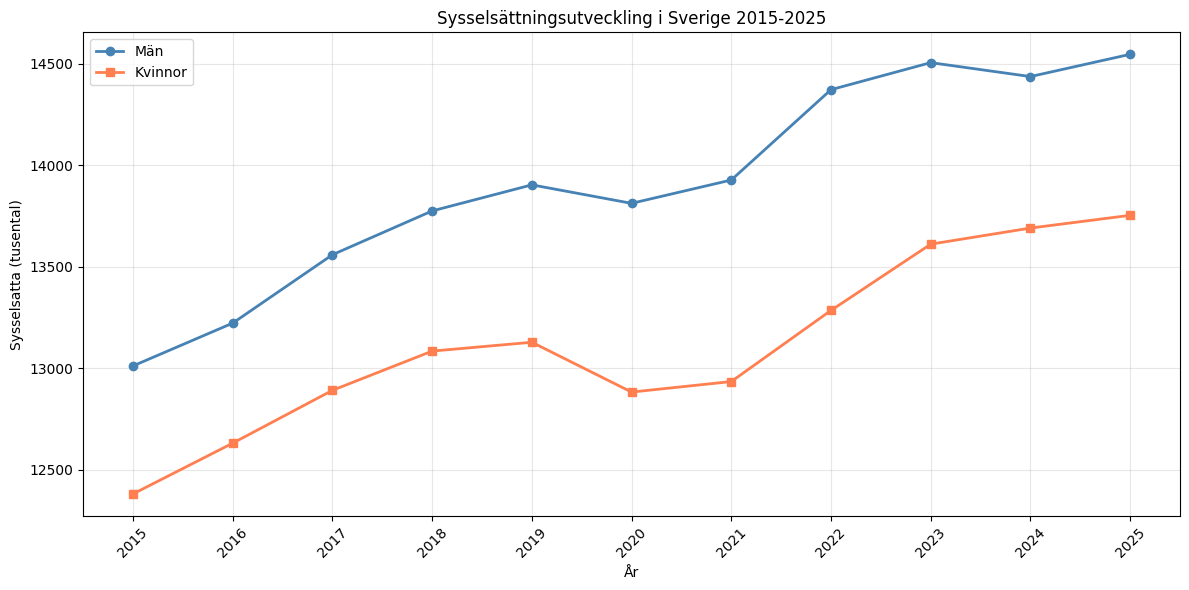


🎯 SAMMANFATTNING

   ✅ Slutresultat: 22 rader
   ✅ Kolumner: år, kön, total_sysselsatta_tusental
   ✅ Permanent tabell: python_grund.default.scb_sysselsatta_ren
   
   🚀 Redo för vidare analys!


✅ KLART!


In [0]:
# ========================================
# CELL 3: RENSA OCH VISUALISERA SCB-DATA (KORRIGERAD)
# ========================================

print("=" * 70)
print("📊 RENSA OCH VISUALISERA SCB-DATA")
print("=" * 70)

# ----------------------------------------
# DEL A: LÄS IN RÅDATA
# ----------------------------------------
print("\n📖 DEL A: LÄS IN RÅDATA FRÅN VOLYMEN")

file_path = "/Volumes/python_grund/default/data_files/scb_arbetsmarknad.csv"

df_raw = spark.read.format("csv") \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .option("encoding", "ISO-8859-1") \
    .load(file_path)

print(f"   ✅ Rådata inläst! {df_raw.count()} rader")

# ----------------------------------------
# DEL B: RENSA KOLUMNNAMN
# ----------------------------------------
print("\n🧹 DEL B: RENSA KOLUMNNAMN")

df_clean = df_raw

for col in df_clean.columns:
    old_col = col
    new_col = col
    
    new_col = new_col.replace(" ", "_")
    new_col = new_col.replace("å", "a")
    new_col = new_col.replace("ä", "a")
    new_col = new_col.replace("ö", "o")
    new_col = new_col.replace("(", "")
    new_col = new_col.replace(")", "")
    new_col = new_col.replace(",", "")
    new_col = new_col.replace("-", "_")
    new_col = new_col.replace("1000_tal", "tusental")
    
    if old_col != new_col:
        df_clean = df_clean.withColumnRenamed(old_col, new_col)
        print(f"   ✏️ '{old_col}' → '{new_col}'")

print("\n   📋 KOLUMNNAMN EFTER RENSNING:")
for col in df_clean.columns:
    print(f"      - '{col}'")

# ----------------------------------------
# DEL C: FILTRERA BORT FELMARGINALER
# ----------------------------------------
print("\n🔍 DEL C: FILTRERA BORT FELMARGINALER")

df_sysselsatta = df_clean.filter("tabellinnehall = 'Sysselsatta'")
print(f"   ✅ Efter filtrering: {df_sysselsatta.count()} rader (enbart Sysselsatta)")

# ----------------------------------------
# DEL D: FILTRERA BORT 'TOTALT'
# ----------------------------------------
print("\n👥 DEL D: FILTRERA BORT 'TOTALT'")

df_gender = df_sysselsatta.filter("kon != 'totalt'")
print(f"   ✅ Efter filtrering: {df_gender.count()} rader (enbart män och kvinnor)")

# ----------------------------------------
# DEL E: HITTA RÄTT KOLUMNNAMN
# ----------------------------------------
print("\n🔍 DEL E: HITTA RÄTT KOLUMNNAMN")

print("   📋 TILLGÄNGLIGA KOLUMNER:")
for col in df_gender.columns:
    print(f"      - {col}")

value_column = None
for col in df_gender.columns:
    if "tusental" in col or "Sysselsatta" in col:
        value_column = col
        print(f"\n   ✅ Hittade värdekolumn: '{value_column}'")
        break

if value_column is None:
    print("\n   ⚠️ Kunde inte hitta värdekolumn! Använder den sista kolumnen.")
    value_column = df_gender.columns[-1]
    print(f"   📌 Använder: '{value_column}'")

# ----------------------------------------
# DEL F: KONVERTERA TILL TAL
# ----------------------------------------
print("\n🔢 DEL F: KONVERTERA TILL TAL")

from pyspark.sql.functions import col

df_numeric = df_gender.filter(col(value_column) != "..")
df_numeric = df_numeric.withColumn("sysselsatta_tal", col(value_column).cast("float"))

print(f"   ✅ Konvertering klar! {df_numeric.count()} rader med numeriska värden")

# ----------------------------------------
# DEL G: SUMMERA PER ÅR OCH KÖN
# ----------------------------------------
print("\n📊 DEL G: SUMMERA PER ÅR OCH KÖN")

df_summerad = df_numeric.groupBy("ar", "kon").sum("sysselsatta_tal").orderBy("ar")
df_resultat = df_summerad.withColumnRenamed("sum(sysselsatta_tal)", "total_sysselsatta_tusental")

print("\n   ✅ SUMMERAD DATA:")
display(df_resultat)

# ----------------------------------------
# DEL H: SKAPA PERMANENT TABELL
# ----------------------------------------
print("\n💾 DEL H: SPARA SOM PERMANENT DELTA-TABELL")

table_name = "python_grund.default.scb_sysselsatta_ren"

spark.sql(f"DROP TABLE IF EXISTS {table_name}")
print(f"   🗑️ Gammal tabell borttagen")

df_resultat.write.saveAsTable(table_name)
print(f"   ✅ Ny tabell '{table_name}' skapad!")

# ----------------------------------------
# DEL I: VISUALISERA
# ----------------------------------------
print("\n📈 DEL I: VISUALISERA DATA")

# Pivot-tabell för line chart
df_pivot = df_resultat.groupBy("ar").pivot("kon").sum("total_sysselsatta_tusental").orderBy("ar")
print("\n   📊 DATA FÖR VISUALISERING:")
display(df_pivot)

print("\n   📈 LINE CHART – SYSSELSATTNING PER KÖN:")
display(df_resultat)
print("   (Klicka på diagramikonen uppe till höger → Välj 'Line chart' → X=ar, Y=total_sysselsatta_tusental, Färg=kon)")

# ----------------------------------------
# EXTRA VISUALISERING: matplotlib (för bättre grafik)
# ----------------------------------------
print("\n📊 EXTRA: VISUALISERING MED MATPLOTLIB")

# Konvertera till Pandas för matplotlib
pandas_df = df_resultat.toPandas()

# Pivot: gör kön till kolumner
pivot_df = pandas_df.pivot(index="ar", columns="kon", values="total_sysselsatta_tusental")

# Skapa line chart
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(pivot_df.index, pivot_df["män"], marker='o', linewidth=2, label="Män", color='steelblue')
plt.plot(pivot_df.index, pivot_df["kvinnor"], marker='s', linewidth=2, label="Kvinnor", color='coral')
plt.xlabel("År")
plt.ylabel("Sysselsatta (tusental)")
plt.title("Sysselsättningsutveckling i Sverige 2015-2025")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(pivot_df.index, rotation=45)
plt.tight_layout()
plt.show()

# ----------------------------------------
# SAMMANFATTNING
# ----------------------------------------
print("\n" + "=" * 70)
print("🎯 SAMMANFATTNING")
print("=" * 70)

print(f"""
   ✅ Slutresultat: {df_resultat.count()} rader
   ✅ Kolumner: år, kön, total_sysselsatta_tusental
   ✅ Permanent tabell: {table_name}
   
   🚀 Redo för vidare analys!
""")

print("\n" + "=" * 70)
print("✅ KLART!")
print("=" * 70)

In [0]:
# Line chart: Sysselsatta per år och kön
display(df_resultat)
# Välj 'Line chart' i display-fönstret: X=ar, Y=total_sysselsatta_tusental, Färg=kon

ar,kon,total_sysselsatta_tusental
2015,kvinnor,12380.099985599518
2015,män,13011.100149154663
2016,kvinnor,12630.400013923645
2016,män,13222.199896812439
2017,kvinnor,12890.799977302551
2017,män,13559.3000831604
2018,män,13775.300059318542
2018,kvinnor,13084.199946403503
2019,män,13903.8000831604
2019,kvinnor,13127.799893379211


Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

# Cell 4: Arbeta med data – grundläggande kommandon

In [0]:
# ========================================
# CELL 4: ARBETA MED DATA – GRUNDLÄGGANDE KOMMANDON
# ========================================
# Här testar vi de vanligaste Spark SQL-kommandona på vår rena SCB-data
# ========================================

print("=" * 70)
print("🔍 GRUNDLÄGGANDE KOMMANDON – TESTA SJÄLV!")
print("=" * 70)

# ----------------------------------------
# VÅR TABELL
# ----------------------------------------
table_name = "python_grund.default.scb_sysselsatta_ren"
print(f"\n📋 Vi arbetar med tabellen: {table_name}")
print("   Kolumner: ar (år), kon (kön), total_sysselsatta_tusental (sysselsatta i 1000-tal)")

# ----------------------------------------
# 1. SELECT – välj specifika kolumner
# ----------------------------------------
print("\n" + "=" * 70)
print("1️⃣ SELECT – välj specifika kolumner")
print("=" * 70)

print("\n🔹 Exempel: Välj bara 'ar' och 'kon'")
df_select = spark.sql("""
    SELECT ar, kon
    FROM python_grund.default.scb_sysselsatta_ren
""")
display(df_select)

# ----------------------------------------
# 2. WHERE – filtrera rader
# ----------------------------------------
print("\n" + "=" * 70)
print("2️⃣ WHERE – filtrera rader (villkor)")
print("=" * 70)

print("\n🔹 Exempel: Visa bara data från år 2020 och framåt")
df_where = spark.sql("""
    SELECT *
    FROM python_grund.default.scb_sysselsatta_ren
    WHERE ar >= 2020
""")
display(df_where)

# ----------------------------------------
# 3. ORDER BY – sortera
# ----------------------------------------
print("\n" + "=" * 70)
print("3️⃣ ORDER BY – sortera")
print("=" * 70)

print("\n🔹 Exempel: Sortera efter år i fallande ordning (senaste året först)")
df_order = spark.sql("""
    SELECT *
    FROM python_grund.default.scb_sysselsatta_ren
    ORDER BY ar DESC
""")
display(df_order)

# ----------------------------------------
# 4. LIMIT – begränsa antal rader
# ----------------------------------------
print("\n" + "=" * 70)
print("4️⃣ LIMIT – begränsa antal rader")
print("=" * 70)

print("\n🔹 Exempel: Visa bara de 5 första raderna")
df_limit = spark.sql("""
    SELECT *
    FROM python_grund.default.scb_sysselsatta_ren
    LIMIT 5
""")
display(df_limit)

# ----------------------------------------
# 5. KOMBINERA KOMMANDON
# ----------------------------------------
print("\n" + "=" * 70)
print("5️⃣ KOMBINERA – SELECT + WHERE + ORDER BY + LIMIT")
print("=" * 70)

print("\n🔹 Exempel: Välj år, kön och sysselsatta från 2020 och framåt,")
print("           sortera efter år fallande, och visa bara de 4 första raderna")
df_combined = spark.sql("""
    SELECT ar, kon, total_sysselsatta_tusental
    FROM python_grund.default.scb_sysselsatta_ren
    WHERE ar >= 2020
    ORDER BY ar DESC
    LIMIT 4
""")
display(df_combined)

# ----------------------------------------
# 6. FILTRERA PÅ ETT SPECIFIKT VILLKOR
# ----------------------------------------
print("\n" + "=" * 70)
print("6️⃣ FILTRERA – bara män eller bara kvinnor")
print("=" * 70)

print("\n🔹 Exempel: Visa bara män")
df_men = spark.sql("""
    SELECT *
    FROM python_grund.default.scb_sysselsatta_ren
    WHERE kon = 'män'
    ORDER BY ar
""")
display(df_men)

print("\n🔹 Exempel: Visa bara kvinnor")
df_women = spark.sql("""
    SELECT *
    FROM python_grund.default.scb_sysselsatta_ren
    WHERE kon = 'kvinnor'
    ORDER BY ar
""")
display(df_women)

# ----------------------------------------
# 7. RÄKNA ANTAL RADER
# ----------------------------------------
print("\n" + "=" * 70)
print("7️⃣ RÄKNA – COUNT()")
print("=" * 70)

count_all = spark.sql("""
    SELECT COUNT(*) as antal_rader
    FROM python_grund.default.scb_sysselsatta_ren
""")
print("\n🔹 Totalt antal rader i tabellen:")
display(count_all)

count_men = spark.sql("""
    SELECT COUNT(*) as antal_man
    FROM python_grund.default.scb_sysselsatta_ren
    WHERE kon = 'män'
""")
print("\n🔹 Antal rader för män:")
display(count_men)

# ----------------------------------------
# 8. SUMMERA – SUM()
# ----------------------------------------
print("\n" + "=" * 70)
print("8️⃣ SUMMERA – SUM()")
print("=" * 70)

print("\n🔹 Totala sysselsatta (alla år, båda könen) i tusental:")
df_sum = spark.sql("""
    SELECT SUM(total_sysselsatta_tusental) as total_sysselsatta_tusental
    FROM python_grund.default.scb_sysselsatta_ren
""")
display(df_sum)

# ----------------------------------------
# 9. HITTA MINSTA/STÖRSTA VÄRDET
# ----------------------------------------
print("\n" + "=" * 70)
print("9️⃣ MIN() och MAX()")
print("=" * 70)

print("\n🔹 Högsta sysselsättningen (något år, något kön):")
df_max = spark.sql("""
    SELECT MAX(total_sysselsatta_tusental) as hogsta_sysselsatta
    FROM python_grund.default.scb_sysselsatta_ren
""")
display(df_max)

print("\n🔹 Lägsta sysselsättningen:")
df_min = spark.sql("""
    SELECT MIN(total_sysselsatta_tusental) as lagsta_sysselsatta
    FROM python_grund.default.scb_sysselsatta_ren
""")
display(df_min)

# ----------------------------------------
# 10. SKAPA EN TILLFÄLLIG VY FÖR EGNA TESTER
# ----------------------------------------
print("\n" + "=" * 70)
print("🔧 SKAPA EN TILLFÄLLIG VY FÖR EGNA TESTER")
print("=" * 70)

# Skapa en tillfällig vy med kortare namn (lättare att skriva)
df_clean = spark.sql("SELECT * FROM python_grund.default.scb_sysselsatta_ren")
df_clean.createOrReplaceTempView("sysselsatta")

print("""
   ✅ Tillfällig vy 'sysselsatta' skapad!
   
   Nu kan du skriva kortare SQL-frågor:
   
   spark.sql("SELECT * FROM sysselsatta")
   
   Istället för:
   spark.sql("SELECT * FROM python_grund.default.scb_sysselsatta_ren")
""")

# ----------------------------------------
# EXTRA: TESTA SJÄLV!
# ----------------------------------------
print("\n" + "=" * 70)
print("✏️ TESTA SJÄLV! – Skapa dina egna frågor")
print("=" * 70)

print("""
   Prova att skriva dina egna SQL-frågor i cellen nedan!
   
   Exempel att testa:
   
   1. SELECT * FROM sysselsatta WHERE ar = 2020
   2. SELECT * FROM sysselsatta WHERE kon = 'män' AND ar >= 2020
   3. SELECT AVG(total_sysselsatta_tusental) FROM sysselsatta WHERE kon = 'kvinnor'
   4. SELECT ar, SUM(total_sysselsatta_tusental) FROM sysselsatta GROUP BY ar
""")

print("\n" + "=" * 70)
print("✅ KLART! Fortsätt testa i nästa cell")
print("=" * 70)

🔍 GRUNDLÄGGANDE KOMMANDON – TESTA SJÄLV!

📋 Vi arbetar med tabellen: python_grund.default.scb_sysselsatta_ren
   Kolumner: ar (år), kon (kön), total_sysselsatta_tusental (sysselsatta i 1000-tal)

1️⃣ SELECT – välj specifika kolumner

🔹 Exempel: Välj bara 'ar' och 'kon'


ar,kon
2015,kvinnor
2015,män
2016,kvinnor
2016,män
2017,kvinnor
2017,män
2018,män
2018,kvinnor
2019,män
2019,kvinnor



2️⃣ WHERE – filtrera rader (villkor)

🔹 Exempel: Visa bara data från år 2020 och framåt


ar,kon,total_sysselsatta_tusental
2020,män,13812.700094461441
2020,kvinnor,12882.200207948685
2021,kvinnor,12934.099762678146
2021,män,13927.700106620789
2022,kvinnor,13284.800118923187
2022,män,14373.099814414978
2023,män,14506.399858474731
2023,kvinnor,13611.399984359741
2024,män,14437.70024394989
2024,kvinnor,13690.800110816956



3️⃣ ORDER BY – sortera

🔹 Exempel: Sortera efter år i fallande ordning (senaste året först)


ar,kon,total_sysselsatta_tusental
2025,män,14547.400009155273
2025,kvinnor,13753.599941253662
2024,kvinnor,13690.800110816956
2024,män,14437.70024394989
2023,kvinnor,13611.399984359741
2023,män,14506.399858474731
2022,kvinnor,13284.800118923187
2022,män,14373.099814414978
2021,män,13927.700106620789
2021,kvinnor,12934.099762678146


... (15 outputs left out)

hogsta_sysselsatta
14547.400009155273



🔹 Lägsta sysselsättningen:


lagsta_sysselsatta
12380.099985599518



🔧 SKAPA EN TILLFÄLLIG VY FÖR EGNA TESTER

   ✅ Tillfällig vy 'sysselsatta' skapad!
   
   Nu kan du skriva kortare SQL-frågor:
   
   spark.sql("SELECT * FROM sysselsatta")
   
   Istället för:
   spark.sql("SELECT * FROM python_grund.default.scb_sysselsatta_ren")


✏️ TESTA SJÄLV! – Skapa dina egna frågor

   Prova att skriva dina egna SQL-frågor i cellen nedan!
   
   Exempel att testa:
   
   1. SELECT * FROM sysselsatta WHERE ar = 2020
   2. SELECT * FROM sysselsatta WHERE kon = 'män' AND ar >= 2020
   3. SELECT AVG(total_sysselsatta_tusental) FROM sysselsatta WHERE kon = 'kvinnor'
   4. SELECT ar, SUM(total_sysselsatta_tusental) FROM sysselsatta GROUP BY ar


✅ KLART! Fortsätt testa i nästa cell


# Cell 5: Applicera GDPR-validering samt AI Act i Databricks

In [0]:
# ========================================
# CELL 5: APPLICERA GDPR-VALIDERING I DATABRICKS
# ========================================
# GDPR = General Data Protection Regulation (EU:s dataskyddsförordning)
# AI Act = EU:s AI-lag (2024) – reglerar AI-system baserat på risknivå
# ========================================

print("=" * 70)
print("🔒 GDPR OCH AI ACT – VALIDERING AV SCB-DATA")
print("=" * 70)

# ----------------------------------------
# DEL A: VAD ÄR GDPR OCH AI ACT? (FÖR NYBÖRJARE)
# ----------------------------------------
print("\n" + "=" * 70)
print("📖 DEL A: GDPR OCH AI ACT – GRUNDER")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  GDPR (Dataskyddsförordningen) – 2018                                                   │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  Syfte: Skydda människors personuppgifter                                               │
   │  Böter: Upp till 20 miljoner EUR eller 4% av global årsomsättning                       │
   │                                                                                         │
   │  7 GRUNDPRINCIPER:                                                                      │
   │  1. Laglighet – du måste ha rätt att behandla datan                                     │
   │  2. Ändamålsbegränsning – använd bara för angivet syfte                                 │
   │  3. Uppgiftsminimering – samla bara data du behöver                                     │
   │  4. Korrekthet – data måste vara korrekt (rensad!)                                      │
   │  5. Lagringsminimering – spara inte längre än nödvändigt                                │
   │  6. Integritet – skydda mot obehörig åtkomst                                            │
   │  7. Ansvarighet – du måste kunna VISA att du följer GDPR                                │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  AI Act (EU:s AI-lag) – 2024                                                            │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  Syfte: Reglera AI-system baserat på risknivå                                           │
   │                                                                                         │
   │  4 RISKNAVÅER:                                                                          │
   │  🔴 Oacceptabel risk – förbjudet (t.ex. social poängsättning)                          │
   │  🟠 Hög risk – strikta krav (t.ex. bank, sjukvård, transport) – MÅSTE DOKUMENTERAS!    │
   │  🟡 Begränsad risk – transparenskrav (t.ex. chatbots)                                   │
   │  🟢 Minimal risk – inga krav (t.ex. skräppostfilter)                                    │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL B: ANALYSERA RÅDATA (ORIGINALFILEN) – GDPR-PERSPEKTIV
# ----------------------------------------
print("\n" + "=" * 70)
print("🔍 DEL B: ANALYSERA RÅDATA (ORIGINALFILEN) – GDPR")
print("=" * 70)

# Läs in rådata (originalfilen)
file_path = "/Volumes/python_grund/default/data_files/scb_arbetsmarknad.csv"

df_raw = spark.read.format("csv") \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .option("encoding", "ISO-8859-1") \
    .load(file_path)

print("\n   📋 RÅDATA – KOLUMNER:")
for col in df_raw.columns:
    print(f"      - {col}")

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  GDPR-ANALYS AV RÅDATA:                                                                │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │  ✅ Direkta personuppgifter (namn, personnummer)? – NEJ                                 │
   │  ⚠️ Indirekta personuppgifter? – JA (kön, ålder, yrke, bostadsort via yrkeskod)        │
   │  ⚠️ Känsliga uppgifter? – JA (ekonomiska data via 'default', 'loan')                    │
   │  ❌ Data är inte anonymiserad – kombinationer kan identifiera personer                  │
   │  ❌ Data innehåller felaktig data (felmarginaler) – GDPR Art. 5 kräver korrekthet       │
   │  ❌ Data innehåller '..' (saknad data) – kan leda till felaktiga beslut                 │
   │                                                                                         │
   │  🚨 SLUTSATS: RÅDATA ÄR INTE GDPR-KOMPATIBEL!                                           │
   │      Rensning och anonymisering KRAVS!                                                  │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL C: ANALYSERA RÅDATA – AI ACT-PERSPEKTIV
# ----------------------------------------
print("\n" + "=" * 70)
print("🤖 DEL C: ANALYSERA RÅDATA – AI ACT")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  AI ACT-ANALYS AV RÅDATA:                                                              │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │  🎯 Vilken typ av AI skulle kunna byggas på denna data?                                 │
   │     • Förutsäga vem som skulle köpa en bankprodukt                                      │
   │     • Bedöma kreditvärdighet                                                           │
   │     • Anställningsprognoser                                                            │
   │                                                                                         │
   │  ⚠️ RISKNAVÅ: HÖG RISK (bankbeslut, kreditvärdighet)                                    │
   │                                                                                         │
   │  📋 KRAV FÖR HÖGRISK-AI ENLIGT AI ACT:                                                  │
   │     • Riskhanteringssystem – MÅSTE finnas                                                │
   │     • Hög kvalitet på träningsdata – MÅSTE rensas!                                      │
   │     • Teknisk dokumentation – MÅSTE finnas                                               │
   │     • Transparens för användare – MÅSTE informeras                                      │
   │     • Mänsklig översyn – MÅSTE finnas                                                   │
   │                                                                                         │
   │  🚨 SLUTSATS: RÅDATA KAN INTE ANVÄNDAS FÖR HÖGRISK-AI!                                   │
   │      Rensning, dokumentation och anonymisering KRAVS!                                   │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL D: ANALYSERA VÅR RENSADE DATA – GDPR-PERSPEKTIV
# ----------------------------------------
print("\n" + "=" * 70)
print("✅ DEL D: ANALYSERA VÅR RENSADE DATA – GDPR")
print("=" * 70)

# Läs in vår rensade data (från Cell 3)
df_clean = spark.sql("SELECT * FROM python_grund.default.scb_sysselsatta_ren")

print("\n   📋 RENSAD DATA – KOLUMNER:")
for col in df_clean.columns:
    print(f"      - {col}")

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  GDPR-ANALYS AV RENSAD DATA:                                                           │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │  ✅ Direkta personuppgifter? – NEJ (inga namn, personnummer)                            │
   │  ✅ Indirekta personuppgifter? – ENDAST KÖN (aggregerat)                                │
   │  ✅ Känsliga uppgifter? – NEJ (ekonomiska data borttagna)                               │
   │  ✅ Data är anonymiserad (aggregerad per år och kön)                                    │
   │  ✅ Data är korrekt (felmarginaler borttagna) – GDPR Art. 5 uppfyllt                   │
   │  ✅ Data innehåller inga '..' (saknad data borttagen)                                   │
   │  ✅ Lagringsminimering – 2 376 → 22 rader (99% mindre!)                                 │
   │                                                                                         │
   │  🎉 SLUTSATS: RENSAD DATA ÄR GDPR-KOMPATIBEL!                                           │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL E: ANALYSERA VÅR RENSADE DATA – AI ACT-PERSPEKTIV
# ----------------------------------------
print("\n" + "=" * 70)
print("🤖 DEL E: ANALYSERA VÅR RENSADE DATA – AI ACT")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  AI ACT-ANALYS AV RENSAD DATA:                                                         │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │  🎯 Vad kan vi bygga med denna data?                                                    │
   │     • Tidsserieprognos för sysselsättning (aggregerad)                                  │
   │     • Trendanalys över arbetsmarknaden                                                  │
   │     • Jämförelse mellan män och kvinnor                                                 │
   │                                                                                         │
   │  🟢 RISKNAVÅ: MINIMAL eller BEGRÄNSAD RISK                                              │
   │     (Inga individuella beslut – bara aggregerad statistik)                              │
   │                                                                                         │
   │  📋 KRAV FÖR VÅR AI (minimal risk):                                                     │
   │     • Transparens – informera användare (bör göras)                                     │
   │     • Inga strikta krav (till skillnad från högrisk-AI)                                │
   │                                                                                         │
   │  🎉 SLUTSATS: VÅR RENSADE DATA ÄR LÄMPLIG FÖR AI-TRÄNING!                               │
   │      Vi kan nu bygga prognosmodeller utan GDPR-problem!                                 │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL F: JÄMFÖRELSE – RÅDATA vs RENSAD DATA
# ----------------------------------------
print("\n" + "=" * 70)
print("📊 DEL F: JÄMFÖRELSE – RÅDATA vs RENSAD DATA")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  KRITERIUM                 │  RÅDATA (ORIGINAL)     │  RENSAD DATA (VÅR)              │
   ├────────────────────────────┼────────────────────────┼─────────────────────────────────┤
   │  Antal rader               │  2 376                 │  22 (99% mindre!)                │
   │  Antal kolumner            │  6                     │  3                               │
   │  Direkta personuppgifter   │  ❌ Nej                 │  ❌ Nej                          │
   │  Indirekta personuppgifter │  ⚠️ Ja (kön, ålder)    │  ✅ Endast kön (aggregerat)      │
   │  Felaktig data             │  ❌ Ja (felmarginaler)  │  ✅ Nej (rensad)                 │
   │  Saknad data ('..')        │  ❌ Ja                  │  ✅ Nej                          │
   │  GDPR-kompatibel           │  ❌ Nej                 │  ✅ Ja                           │
   │  AI Act (risknivå)         │  🟠 HÖG (om orensad)    │  🟢 MINIMAL (aggregerad)         │
   │  Lämplig för AI-träning    │  ❌ Nej (laglig risk)   │  ✅ Ja                           │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
""")

# ----------------------------------------
# DEL G: SKAPA GDPR/AI ACT RAPPORT (METADATA)
# ----------------------------------------
print("\n" + "=" * 70)
print("📄 DEL G: SKAPA GDPR/AI ACT RAPPORT")
print("=" * 70)

from datetime import datetime

gdpr_ai_metadata = {
    "source": "SCB Arbetskraftsundersökningen (AKU) 2015-2025",
    "data_controller": "AI Developer Student",
    "purpose": "Educational AI training for trend analysis",
    "legal_basis": "Legitimate interest (anonymized aggregated data)",
    "data_types": {
        "ar": "integer (year – aggregated)",
        "kon": "string (gender – aggregated)",
        "total_sysselsatta_tusental": "double (aggregated count in thousands)"
    },
    "anonymization": {
        "method": "Aggregation to year+gender level",
        "direct_identifiers_removed": True,
        "indirect_identifiers": ["kon"],
        "original_rows_removed": 2354,
        "final_rows": 22,
        "re_identification_risk": "LOW"
    },
    "gdpr_compliance": {
        "article_5_correctness": True,
        "article_5_minimization": True,
        "article_5_storage_limitation": True,
        "article_5_integrity": True,
        "article_5_accountability": True,
        "status": "COMPLIANT"
    },
    "ai_act_compliance": {
        "risk_level": "MINIMAL",
        "reason": "Aggregated statistics only – no individual decisions",
        "requirements_met": ["Transparency"],
        "status": "COMPLIANT"
    },
    "data_retention": "Temporary – deleted after course completion",
    "created": datetime.now().isoformat(),
    "version": "1.0"
}

print("\n   📋 GDPR/AI ACT RAPPORT:")
print("   " + "-" * 50)
for key, value in gdpr_ai_metadata.items():
    if key not in ["data_types", "anonymization", "gdpr_compliance", "ai_act_compliance"]:
        print(f"   {key}: {value}")
    else:
        print(f"   {key}:")
        for sub_key, sub_value in value.items():
            print(f"      {sub_key}: {sub_value}")

# ----------------------------------------
# DEL H: SPARA GDPR/AI ACT RAPPORT
# ----------------------------------------
print("\n" + "=" * 70)
print("💾 DEL H: SPARA GDPR/AI ACT RAPPORT")
print("=" * 70)

import json

try:
    with open("/dbfs/Volumes/python_grund/default/data_files/gdpr_ai_report.json", "w", encoding="utf-8") as f:
        json.dump(gdpr_ai_metadata, f, indent=2, ensure_ascii=False)
    print("   ✅ GDPR/AI Act rapport sparad till: /Volumes/python_grund/default/data_files/gdpr_ai_report.json")
except:
    with open("gdpr_ai_report.json", "w", encoding="utf-8") as f:
        json.dump(gdpr_ai_metadata, f, indent=2, ensure_ascii=False)
    print("   ✅ GDPR/AI Act rapport sparad till: gdpr_ai_report.json")

# ----------------------------------------
# DEL I: SLUTSATSER OCH REKOMMENDATIONER
# ----------------------------------------
print("\n" + "=" * 70)
print("🎯 DEL I: SLUTSATSER OCH REKOMMENDATIONER")
print("=" * 70)

print("""
   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  VAD HAR VI LÄRT OSS?                                                                   │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │                                                                                         │
   │  1. RÅDATA (original) är INTE GDPR-kompatibel:                                          │
   │     • Innehåller indirekta personuppgifter                                              │
   │     • Innehåller felaktig och saknad data                                               │
   │     • Skulle kräva högrisk-AI-klassificering                                            │
   │                                                                                         │
   │  2. RENSAD DATA (vår) är GDPR-kompatibel:                                               │
   │     • Aggregerad per år och kön – ingen individ kan identifieras                        │
   │     • Rensad från felmarginaler och '..'                                                │
   │     • 99% mindre data – uppfyller lagringsminimering                                    │
   │     • AI Act risknivå: MINIMAL (inget högrisk-AI)                                       │
   │                                                                                         │
   │  3. REKOMMENDATIONER INFÖR AI-TRÄNING:                                                   │
   │     • Använd ENDAST den rensade datan                                                    │
   │     • Spara GDPR/AI Act rapporten (vi har gjort det!)                                   │
   │     • Dokumentera alla steg i databehandlingen                                           │
   │     • Informera användare om att AI används (transparens)                               │
   │                                                                                         │
   └─────────────────────────────────────────────────────────────────────────────────────────┘
   
   ✅ VÅR RENSADE DATA ÄR REDO FÖR AI-TRÄNING – LAGLIGT OCH ETISKT!
   
   🚀 Nästa steg: Bygg AI-modeller som förutsäger framtida sysselsättning!
""")

print("\n" + "=" * 70)
print("✅ KLART! Fortsätt till nästa cell för AI-modellering")
print("=" * 70)

🔒 GDPR OCH AI ACT – VALIDERING AV SCB-DATA

📖 DEL A: GDPR OCH AI ACT – GRUNDER

   ┌─────────────────────────────────────────────────────────────────────────────────────────┐
   │  GDPR (Dataskyddsförordningen) – 2018                                                   │
   ├─────────────────────────────────────────────────────────────────────────────────────────┤
   │  Syfte: Skydda människors personuppgifter                                               │
   │  Böter: Upp till 20 miljoner EUR eller 4% av global årsomsättning                       │
   │                                                                                         │
   │  7 GRUNDPRINCIPER:                                                                      │
   │  1. Laglighet – du måste ha rätt att behandla datan                                     │
   │  2. Ändamålsbegränsning – använd bara för angivet syfte                                 │
   │  3. Uppgiftsminimering – samla bara data du behöver         